# Arbeitspaket (AP) 2: Datenbeschaffung, Datenaufbereitung & explorative Datenanalyse

### Persönliche Angaben (bitte ergänzen) und Prüfungsregeln

<table>
  <tr><td>Vorname:</td><td>Iris</td></tr>
  <tr><td>Nachname:</td><td></td></tr>
  <tr><td>Immatrikulationsnummer:</td><td></td></tr>
  <tr><td>Modul:</td><td>Data Science</td></tr>
  <tr><td>Prüfungsdatum / Raum / Zeit:</td><td>[TT.MM.2026] / Raum: [anpassen] / [hh:mm – hh:mm]</td></tr>
  <tr><td>Erlaubte Hilfsmittel:</td><td>Es gelten die Prüfungsregeln (PDF-Dokument auf EXAM-Moodle).</td></tr>
  <tr><td>Nicht erlaubt:</td><td>Es gelten die Prüfungsregeln (PDF-Dokument auf EXAM-Moodle).</td></tr>
  <tr><td>Technische Probleme:</td><td>Wenden Sie sich bei technischen Problemen umgehend an die Prüfungsaufsicht.</td></tr>
</table>

## Bewertungskriterien

**(max. erreichbare Punkte: 40)**

<table>
  <thead>
    <tr><th>Teil</th><th>Thema</th><th>Aufgaben</th><th>Punkte</th></tr>
  </thead>
  <tbody>
    <tr><td>A</td><td>Konzeptfragen: Datenaufbereitung &amp; explorative Datenanalyse</td><td>A1–A3</td><td>12</td></tr>
    <tr><td>B</td><td>Fehleranalyse Python-Code (Shop-Daten)</td><td>B1–B2</td><td>16</td></tr>
    <tr><td>C</td><td>Python-Code schreiben: Web Scraping, Datenaufbereitung &amp; EDA</td><td>C1–C3</td><td>12</td></tr>
    <tr><td><b>Total</b></td><td></td><td><b>8 Aufgaben</b></td><td><b>40</b></td></tr>
  </tbody>
</table>

### Bewertungsschema

Jede Aufgabe wird für sich und **als Ganzes** bewertet. Ihre Punktzahl steht in der Überschrift.

<table>
  <thead>
    <tr><th>Kategorie</th><th>Beschreibung</th><th>Bewertung</th><th>4 Pkt</th><th>8 Pkt</th></tr>
  </thead>
  <tbody>
    <tr><td>Korrekt</td><td>Vollständig und fachlich einwandfrei: Antwort bzw. Begründung korrekt und nachvollziehbar; bei Code-Aufgaben liefert der Python-Code das richtige Ergebnis</td><td>100%</td><td>4</td><td>8</td></tr>
    <tr><td>Minimale Mängel</td><td>Kleine Fehler (z.B. falsche Sortierung, fehlende Rundung, fehlende Achsenbeschriftung) oder Begründung ungenau bzw. unvollständig</td><td>75%</td><td>3</td><td>6</td></tr>
    <tr><td>Mittlere Mängel</td><td>Grössere Fehler (z.B. fehlende Spalten, falsche Filterung) oder Begründung fehlt bzw. ist fachlich falsch</td><td>50%</td><td>2</td><td>4</td></tr>
    <tr><td>Gravierende Mängel</td><td>Problem bzw. Ansatz erkennbar, aber Lösung oder Schlussfolgerung im Kern falsch (z.B. Problem richtig benannt, aber falsch behoben; im Code: ungeeigneter Lösungsweg wie falscher Join-Typ, falsche Tabelle oder falsche Datei)</td><td>25%</td><td>1</td><td>2</td></tr>
    <tr><td>Nicht lauffähig / nicht sinnvoll</td><td>Antwort fehlt, Code nicht lauffähig (z.B. Syntaxfehler) oder kein Bezug zur Aufgabe</td><td>0%</td><td>0</td><td>0</td></tr>
  </tbody>
</table>

Treffen mehrere Mängel zusammen, zählt der schwerste. Alternative, fachlich korrekte Lösungswege werden ebenfalls als korrekt gewertet.

## Hinweise zu den Daten

Alle Daten stammen vom **fiktiven** Schweizer Online-Shop «PhoneMarkt» und liegen **lokal** im gleichen Verzeichnis wie dieses Notebook. Für die Prüfung ist **kein Internetzugriff** auf Websites oder APIs nötig.

<table>
  <thead>
    <tr><th>Datei</th><th>Format</th><th>Inhalt</th></tr>
  </thead>
  <tbody>
    <tr><td><code>html/shop_page_1.html</code> … <code>shop_page_3.html</code></td><td>HTML</td><td>Gespeicherte Produktlisten-Seiten (3 Seiten mit Paginierung)</td></tr>
    <tr><td><code>html/product_detail.html</code></td><td>HTML</td><td>Gespeicherte Detailseite eines Geräts (Preisverlauf, technische Daten)</td></tr>
    <tr><td><code>reviews.json</code></td><td>JSON</td><td>Gespeicherte Antwort der Reviews-API: Liste mit Kundenbewertungen pro <code>product_id</code></td></tr>
    <tr><td><code>smartphones_clean.csv</code></td><td>CSV</td><td>Aufbereitete Shop-Daten: Formate vereinheitlicht, Duplikate entfernt — <b>inhaltlich nicht geprüft</b></td></tr>
  </tbody>
</table>

Die Spaltenbeschreibungen finden Sie im Sheet **«Description»**, die Datenquellen im Sheet **«Data Sources»** der beiliegenden Datei `smartphone_data.xlsx`. Die HTML-Dateien können Sie zur Ansicht auch im Browser oder als Text im Editor öffnen.

**Antworten auf Konzeptfragen** und **Begründungen** tragen Sie bitte direkt in die vorgesehenen Markdown-Zellen ein.

## Setup (wird nicht bewertet)

In [1]:
# Libraries
import os
import re
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Get current working directory
print(os.getcwd())

/workspaces/DS_HS2026_LNW/DS_HS2026_LNW_I_Examples/AP02


### Produktlisten-Seiten scrapen → `df_raw`

Der folgende Code liest die drei gespeicherten Produktlisten-Seiten mit BeautifulSoup ein (analog zur Übung `skipass_data.ipynb`). Jede Produktkarte (`<div class="product-card">`) wird zu einer Zeile im Data Frame `df_raw`. Die Werte werden **als Text** übernommen (Spalten mit Endung `_raw`) und noch nicht bereinigt.

In [2]:
# Initialize list for the extracted rows
rows = []

# Loop over the three listing pages
for page in [1, 2, 3]:

    # Read html from file
    with open(f'html/shop_page_{page}.html', 'r', encoding='utf-8') as file:
        html_content = file.read()

    # Parse the HTML content
    soup = BeautifulSoup(html_content, 'html.parser')

    # Locate the product cards and extract values
    for card in soup.select('div.product-card'):
        row_data = [card['data-product-id'],
                    card.select('span.brand')[0].get_text().replace('\xa0', '').strip(),
                    card.select('span.model')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.storage')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.color')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.screen')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.battery')[0].get_text().replace('\xa0', '').strip(),
                    card.select('span.price')[0].get_text().replace('\xa0', '').strip(),
                    card.select('span.availability')[0].get_text().replace('\xa0', '').strip()]
        rows.append(row_data)

# Create a DataFrame
df_raw = pd.DataFrame(rows, columns=['product_id', 'brand', 'model', 'storage_raw', 'color',
                                     'screen_raw', 'battery_raw', 'price_raw', 'availability'])

# Show dimensions and first rows
print('Number of rows and columns:', df_raw.shape)
df_raw.head()

Number of rows and columns: (148, 9)


,product_id,brand,model,storage_raw,color,screen_raw,battery_raw,price_raw,availability
0,PM-10001,Xiaomi,Redmi Note 14 Pro 5G,256GB,Midnight Black,"6.67"" Display",5'110mAh,CHF 299.–,Sofort lieferbar
1,PM-10002,OnePlus,OnePlus 13,256GB,Arctic Dawn,"6.82"" Display",6'000mAh,CHF 899.–,Lieferbar in 2–5 Tagen
2,PM-10003,Google,Pixel 10 Pro,512GB,Obsidian,"6.3"" Display",4'870mAh,CHF 1'249.–,Sofort lieferbar
3,PM-10004,Samsung,Galaxy A36 5G,128GB,Awesome Lavender,"6.7"" Display",5'000mAh,CHF 339.–,Sofort lieferbar
4,PM-10005,Samsung,Galaxy Z Fold7,1TB,Jetblack,"8.0"" Display",4'400mAh,Preis auf Anfrage,Vorbestellung


### Aufbereitete Shop-Daten laden → `df_clean`

In [3]:
# Import data from csv to pandas dataframe named 'df_clean'
df_clean = pd.read_csv('smartphones_clean.csv')

# Show dimensions and first rows
print('Number of rows and columns:', df_clean.shape)
df_clean.head()

Number of rows and columns: (142, 9)


,product_id,brand,model,storage_gb,color,screen_inch,battery_mah,price_chf,availability
0,PM-10001,Xiaomi,Redmi Note 14 Pro 5G,256,Midnight Black,6.67,5110,299.0,Sofort lieferbar
1,PM-10002,OnePlus,OnePlus 13,256,Arctic Dawn,6.82,6000,899.0,Lieferbar in 2–5 Tagen
2,PM-10003,Google,Pixel 10 Pro,512,Obsidian,6.30,4870,1249.0,Sofort lieferbar
3,PM-10004,Samsung,Galaxy A36 5G,128,Awesome Lavender,6.70,5000,339.0,Sofort lieferbar
4,PM-10005,Samsung,Galaxy Z Fold7,1024,Jetblack,8.00,4400,NaN,Vorbestellung


> **Hinweis:** Alle Aufgaben sind voneinander unabhängig. Verändern Sie `df_raw` und `df_clean` bitte nicht direkt, sondern arbeiten Sie in jeder Aufgabe mit einem eigenen Data Frame (z.B. `df_B1`, `df_C2`).

---

<div style="background-color:#2E4057; color:white; padding:16px 24px; border-radius:6px; font-size:18px; margin-top:8px;">
&#9654;&nbsp; <strong>Ab hier beginnt die bewertete Prüfung — 40 Punkte</strong><br>
<span style="font-size:15px; font-weight:normal;">Tragen Sie Ihre Antworten direkt in die vorgesehenen Zellen ein und führen Sie alle Code-Zellen aus.</span>
</div>

---
## Teil A – Konzeptfragen (12 Punkte)

*Antworten ohne Bezug zu den Shop-Daten von «PhoneMarkt» werden nicht gewertet.*

### A1 (4 Punkte)

Bei 8 der 142 Geräte zeigt der Shop statt eines Preises den Text «Preis auf Anfrage». Laut Shop-Betreiber wird der Preis ausgeblendet, wenn er eine interne Preisschwelle übersteigt.

a) Um welchen Mechanismus fehlender Werte handelt es sich (MCAR, MAR oder MNAR)? Begründen Sie.

b) Ein Analyst entfernt diese 8 Geräte mit `dropna()` und berichtet anschliessend den durchschnittlichen Gerätepreis des Shops. Welchen Effekt hat das Entfernen auf das Ergebnis?

**Ihre Antwort:**

> In den Shop Daten handelt es sich bei den fehlenden Werten um den MNAR Mechanismus, da das Fehlen einen direkten Zusammenhang mit der fehlenden Varible selbst hat.
> Das Entfernen der Geräte mit fehlendem Preis hat den Effekt, dass es das Ergebnis und die Zusammenhänge verzerrt. Produkte mit einem Preis, welche einen gewissen Schwellenwert übersteigen, kommen nicht mehr in den ausgewerteten Daten vor. Die Erkenntnisse gelten dann somit nur für Produkte bis zu einem gewissen Preisrange.

**Korrigierte Antwort:**
>a) Mechanismus: Es handelt sich um MNAR (Missing Not at Random), da das Fehlen des Preises direkt vom unbeobachteten Wert der Variable price_chf selbst abhängt (Überschreiten einer internen Preisschwelle).
>
>b) Effekt von dropna(): Da gezielt die hochpreisigen Geräte oberhalb der Preisschwelle entfernt werden, wird der berechnete durchschnittliche Gerätepreis des Shops systematisch nach unten verzerrt (unterschätzt) und repräsentiert nur noch das günstigere bis mittlere Sortiment.

### A2 (4 Punkte)

Für die Spalte `price_chf` in `smartphones_clean.csv` liefert pandas folgendes Ergebnis:

```
df_clean['price_chf'].describe()          df_clean['price_chf'].skew()
count      134.00                          9.19
mean       992.89
std       1126.48
min        159.00
25%        479.00
50%        899.00
75%       1199.00
max      12990.00
```

Beschreiben Sie die Verteilung der Preise anhand dieser Kennzahlen. Welches Lagemass eignet sich besser, um den «typischen» Gerätepreis zu berichten, und warum? Nennen Sie eine geeignete Grafik, um Ihre Einschätzung zu überprüfen.

**Ihre Antwort:**

> Ein Histogram oder ein Boxplot würden sich gut für die Veranschaulichung der Verteilung dieser Daten eignen. Grundsätzlich kann mann aber bereits erkennen, dass mean und median nahe beieinander sind. Die Mehrheit der Datenpunkte bzw. Produkte kostet maximal CHF 1199.-. Es gibt jedoch grössere Ausreisser von Produkten, die deutlich mehr als der Durchschnitt oder die Mehrheit der Daten kosten.
> Mit einem skew von 9.19 ist die Verteilung rechtsschief, mit einem langen Ausläufer nach rechts (siehe max Wert von CHF 12990.00).

**Korrigierte Antwort:**
> **Verteilung**: Die Preise sind extrem rechtsschief (skew = 9.19 > 0). Während 75 % der Geräte höchstens CHF 1'199.– kosten (IQR = 1'199 − 479 = CHF 720.–), zieht mindestens ein extremer Ausreisser (max = CHF 12'990.–) den Mittelwert (CHF 992.89) deutlich über den Median (CHF 899.00) und bläht die Standardabweichung (CHF 1'126.48) stark auf.
>
>**Geeignetes Lagemass:** Der Median (CHF 899.00) eignet sich deutlich besser für den typischen Gerätepreis, da er als 50-%-Quantil robust gegenüber Ausreissern und Schiefe ist, während das arithmetische Mittel durch Extremwerte nach oben verzerrt wird.
>
>**Geeignete Grafik:** Ein Boxplot (zeigt Median, IQR und Ausreisser direkt) oder ein Histogramm (zeigt die rechtsschiefe Häufigkeitsverteilung).
>

### A3 (4 Punkte)

Ein Kollege verbindet die Shop-Daten mit den Kundenbewertungen aus `reviews.json` und berechnet die Korrelation zwischen `price_chf` und `avg_score` (Durchschnitt der Kundenbewertungen, 1–5 Sterne):

```
df[['price_chf', 'avg_score']].corr()     # Ergebnis: r = 0.34
```

Er folgert: *«Preis und Kundenzufriedenheit hängen kaum zusammen.»*

Nennen und begründen Sie **zwei** fachliche Einwände gegen diese Vorgehensweise bzw. Schlussfolgerung.

**Ihre Antwort:**

> 1. Eine tiefe Korrelation schliesst per se noch keinen Kausalzusammenhang aus. Eine weitere Variable könnte auf Resultat eifluss haben.
> 2. avg_score enthält Kategoriale Werte, welche von .corr() nicht direkt verwendet werden sollten.

**Korrigierte Antwort:** 
> 1. Nur lineare Zusammenhänge & Ausreisser-Sensitivität: Der Pearson-Korrelationskoeffizient (df.corr()) erfasst ausschliesslich lineare Zusammenhänge und reagiert empfindlich auf Ausreisser (wie den Preis-Ausreisser von CHF 12'990.–). Ein starker nicht-linearer Zusammenhang (z. B. Sättigungskurve) kann dennoch zu einem niedrigen $r = 0.34$ führen – ohne Streudiagramm (vgl. Anscombe's Quartet) ist die Kennzahl nicht aussagekräftig.
> 2. Skalenniveau (Ordinaldaten) & Gewichtungsproblem: Kundenbewertungen (1–5 Sterne) basieren auf einer Ordinalskala (keine metrisch gleichen Abstände zwischen den Bewertungsstufen) und sind häufig schief verteilt, weshalb statt Pearson eine Rangkorrelation (Spearman) angebracht ist. Zudem ignoriert avg_score die Anzahl abgegebener Bewertungen pro Produkt (ein Gerät mit 1 Bewertung zählt gleich viel wie eines mit 100 Bewertungen) und schliesst die 8 teuren Geräte ohne Preis (NaN) aus.

---
## Teil B – Fehleranalyse Python-Code (16 Punkte)

*Jeder Code läuft fehlerfrei durch, liefert aber ein falsches oder irreführendes Ergebnis. Die tatsächlichen Ergebnisse sind angegeben.*

### B1 (8 Punkte)

**Ziel:** Kennzahlen für das Shop-Sortiment aus den gescrapten Rohdaten `df_raw`: Anzahl Geräte, Anzahl Geräte ohne Preisangabe und Median-Preis in CHF.

```python
# Select columns for the analysis
df_B1 = df_raw[['product_id', 'brand', 'model', 'storage_raw', 'color', 'price_raw']]

# Extract numerical values from price_raw
price = []
for i in df_B1['price_raw']:
    d1 = re.findall(r"\d+", i)
    try:
        d2 = int(d1[0])
    except:
        d2 = None
    price.append(d2)

# Save as new variable in the pandas data frame
df_B1['price_chf'] = pd.Series(price, dtype="Int64")

# Show key figures
print('Anzahl Geräte:            ', df_B1.shape[0])
print('Anzahl ohne Preisangabe:  ', df_B1['price_chf'].isnull().sum())
print('Median-Preis (CHF):       ', df_B1['price_chf'].median())
```

Tatsächliches Ergebnis:

```
Anzahl Geräte:             148
Anzahl ohne Preisangabe:   8
Median-Preis (CHF):        314.0
```

Der Shop gibt auf jeder Seite an, dass er **142 Artikel** führt. Beispiele für Werte in `price_raw`: `CHF 899.–`, `CHF 1'249.–`, `Preis auf Anfrage`.

**Aufgabe:** Schreiben Sie den korrigierten Code in die Zelle «Korrigierter Code» (die Kommentare des ursprünglichen Codes sind als Gerüst vorgegeben), sodass die Kennzahlen stimmen. Begründen Sie jede Änderung gegenüber dem ursprünglichen Code.

**Begründung der Änderungen:**

> Regex Reihenfolge geändert damit CHF und .- als Anker genutzt werden. Strikte tausender-trennung wird mit dieser Regex Reihenfolge überprüft. Trennzeichen werden in einem weiteren Schritt mit .strip() und .replace() ersetzt.
>
**Korrektur der Antwort:**
> 1. Duplikate entfernen (.drop_duplicates()): Beim Scraping der drei Paginierungsseiten wurden 6 Produkte doppelt erfasst (148 statt der vom Shop angegebenen 142 Artikel). Durch df_B1 = df_B1.drop_duplicates() (oder .drop_duplicates(subset=['product_id'])) wird jedes Gerät nur einmal gezählt.
> 2. Tausender-Apostroph beim Regex-Parsing berücksichtigen: re.findall(r"\d+", "CHF 1'249.–") lieferte die Liste ['1', '249'], wovon d1[0] nur die 1 übernahm und alle Geräte ab CHF 1'000.– fälschlicherweise als CHF 1.– bis 12.– einstufte. Durch das Entfernen des Tausender-Apostrophs (i.replace("'", "")) bzw. das Erfassen des gesamten Preisausdrucks wird 1'249 korrekt als 1249 extrahiert.

**Wichtiger Hinweis**
> Wenn df_B1 nach .drop_duplicates() einen Index mit Lücken hat, stellt index=df_B1.index in pd.Series(...) sicher, dass die Werte exakt den richtigen Zeilen zugeordnet werden!

**Korrigierter Code- hier fehlt drop.duplicates()**

In [4]:
# Korrigierten Code unter den Kommentaren eintragen

# Select columns for the analysis
df_B1 = df_raw[['product_id', 'brand', 'model', 'storage_raw', 'color', 'price_raw']]

# Extract numerical values from price_raw
price = []
for i in df_B1['price_raw']:
    d1 = re.findall(r"CHF\s*(\d{1,3}(?:'\d{3})*)\.–", i)
    try:
        d2 = int(d1[0].strip().replace("'", ""))
    except:
        d2 = None
    price.append(d2)
# Save as new variable in the pandas data frame
df_B1['price_chf'] = pd.Series(price, dtype="Int64")

# Show key figures
print('Anzahl Geräte:            ', df_B1.shape[0])
print('Anzahl ohne Preisangabe:  ', df_B1['price_chf'].isnull().sum())
print('Median-Preis (CHF):       ', df_B1['price_chf'].median())
df_B1.head()


Anzahl Geräte:             148
Anzahl ohne Preisangabe:   8
Median-Preis (CHF):        924.0


,product_id,brand,model,storage_raw,color,price_raw,price_chf
0,PM-10001,Xiaomi,Redmi Note 14 Pro 5G,256GB,Midnight Black,CHF 299.–,299
1,PM-10002,OnePlus,OnePlus 13,256GB,Arctic Dawn,CHF 899.–,899
2,PM-10003,Google,Pixel 10 Pro,512GB,Obsidian,CHF 1'249.–,1249
3,PM-10004,Samsung,Galaxy A36 5G,128GB,Awesome Lavender,CHF 339.–,339
4,PM-10005,Samsung,Galaxy Z Fold7,1TB,Jetblack,Preis auf Anfrage,<NA>


In [5]:
# Musterlösung mit drop.duplicates()
# Select columns for the analysis
df_B1 = df_raw[['product_id', 'brand', 'model', 'storage_raw', 'color', 'price_raw']].drop_duplicates().copy()

# Extract numerical values from price_raw
price = []
for i in df_B1['price_raw']:
    d1 = re.findall(r'\d+', i.replace("'", ""))
    try:
        d2 = int(d1[0])
    except:
        d2 = None
    price.append(d2)

# Save as new variable in the pandas data frame
df_B1['price_chf'] = pd.Series(price, dtype="Int64", index=df_B1.index)

# Show key figures
print('Anzahl Geräte:            ', df_B1.shape[0])
print('Anzahl ohne Preisangabe:  ', df_B1['price_chf'].isnull().sum())
print('Median-Preis (CHF):       ', df_B1['price_chf'].median())

Anzahl Geräte:             142
Anzahl ohne Preisangabe:   8
Median-Preis (CHF):        899.0


### B2 (8 Punkte)

**Ziel:** Herausfinden, welche Marke im Sortiment am teuersten ist (auf Basis von `df_clean`).

```python
# Select columns for the analysis
df_B2 = df_clean[['brand', 'price_chf']]

# Price per brand
df_B2.groupby(['brand']).mean().round(2).sort_values(by='price_chf', ascending=False)
```

Tatsächliches Ergebnis (Ausschnitt):

```
           price_chf
brand
Samsung      1298.70
Apple        1083.71
Sony         1057.33
Google       1054.91
OnePlus       702.75
...
```

Die Produktmanagerin ist skeptisch: *«Samsung hat viele günstige A-Modelle im Sortiment — das kann nicht stimmen.»*

**Aufgabe:** Untersuchen Sie die Daten mit geeigneten EDA-Methoden, finden Sie die Ursache für das irreführende Ergebnis und schreiben Sie den korrigierten Code in die Zelle «Korrigierter Code» (die Kommentare des ursprünglichen Codes sind als Gerüst vorgegeben). Begründen Sie jede Änderung gegenüber dem ursprünglichen Code.

**Begründung der Änderungen:**

> Samsung hat vier fehlende Preise und mindestens einen groben Ausreisser mit einem Betrag von CHF 12'990.00. Da die Preise bewusst bei diesen vier Geräten fehlen, da sie einen gewissen Schwellenwert übersteigen handelt es sich hier um einen MNAR Mechanismus. Hier würde eine Imputation Sinn machen, da der Stichprobenumfang so erhalten bleibt und zudem die Verteilung bereits schief ist. Dies würde die Streuung künstlich verringern.

**Koorigierte Lösung:**
> Die EDA (describe()) zeigt, dass Samsung einen extremen Ausreisser von CHF 12'990.00 aufweist (vermutlich ein Erfassungsfehler für CHF 1'299.00, da 75 % der Samsung-Geräte $\le \text{CHF } 1'224.00$ kosten) und zudem 4 hochpreisige Geräte ohne Preis (NaN, MNAR) hat. Da das arithmetische Mittel (.mean()) extrem empfindlich auf diesen Ausreisser reagiert und Samsung künstlich auf CHF 1'298.70 hochzieht, wird stattdessen der .median() als ausreisserrobustes Lagemass verwendet (und zusätzlich count ausgegeben, um die Stichprobengrösse je Marke transparent zu machen).  

In [6]:
# Saubere Lösung mit .groupby()
# Select columns for the analysis
df_B2 = df_clean[['brand', 'price_chf']].copy()

# Price per brand (Median statt Mean wegen Ausreisser CHF 12'990.–)
df_B2.groupby(['brand'])['price_chf'].agg(
    count='count',
    median_price='median',
    mean_price='mean'
).round(2).sort_values(by='median_price', ascending=False)

,count,median_price,mean_price
brand,,,
Sony,6,1289.0,1057.33
Google,22,1049.0,1054.91
Apple,34,1024.0,1083.71
Samsung,30,999.0,1298.70
Xiaomi,18,719.0,701.78
OnePlus,8,689.0,702.75
Nothing,8,599.0,624.00
Fairphone,2,529.0,529.00
Motorola,6,349.0,564.00


**Korrigierter Code - alte Lösung**

In [34]:
# Korrigierten Code unter den Kommentaren eintragen

# Select columns for the analysis
df_B2 = df_clean[['brand', 'price_chf']]

display(df_B2.isna().sum())
display(df_B2['brand'].describe())
display(df_B2['price_chf'].describe())

display(df_B2['brand'].value_counts())

sub_samsung = df_B2[df_B2['brand'] == 'Samsung']
sub_samsung.head()
display(sub_samsung.isna().sum())
display(sub_samsung.describe())

# Price per brand
#df_B2.groupby(['brand']).mean().round(2).sort_values(by='price_chf', ascending=False)


brand        0
price_chf    8
dtype: int64

count         142
unique          9
top       Samsung
freq           34
Name: brand, dtype: object

count      134.000000
mean       992.888060
std       1126.484235
min        159.000000
25%        479.000000
50%        899.000000
75%       1199.000000
max      12990.000000
Name: price_chf, dtype: float64

brand
Samsung      34
Apple        34
Google       26
Xiaomi       18
OnePlus       8
Nothing       8
Sony          6
Motorola      6
Fairphone     2
Name: count, dtype: int64

brand        0
price_chf    4
dtype: int64

,price_chf
count,30.000000
mean,1298.700000
std,2253.953449
min,199.000000
25%,441.500000
50%,999.000000
75%,1224.000000
max,12990.000000


---
## Teil C – Python-Code schreiben (12 Punkte)

Schreiben Sie Python-Code und begründen Sie Ihre Vorgehensweise jeweils in 1–2 Sätzen. Worauf die Begründung eingehen soll, steht bei der Aufgabe.

### C1 (4 Punkte)

Die Datei `html/product_detail.html` enthält die Detailseite des Google Pixel 10 Pro. In der Code-Zelle ist bereits ein Gerüst vorgegeben, das die HTML-Datei einliest und eine Tabelle Zeile für Zeile in den Data Frame `df_C1` mit den Spalten `merkmal` und `wert` überführt.

Ergänzen Sie die beiden mit `# TODO` markierten Stellen:

1. Wählen Sie die Tabelle **«Technische Daten»** aus.
2. Entfernen Sie die Zwischenüberschriften der Tabelle (z.B. «Display») — sie sind **keine** Merkmale und dürfen im Ergebnis nicht vorkommen.

Begründen Sie, wie Sie die richtige Tabelle auswählen und die Zwischenüberschriften entfernen.

*Tipp: Öffnen Sie die HTML-Datei im Editor und sehen Sie sich `df_C1` vor dem Entfernen der Zwischenüberschriften an.*

**Begründung der Vorgehensweise:**

> Logik der Musterlösung (passend zum vorgegebenen Gerüst):
>
> 1. Tabelle auswählen: In HTML wird die Tabelle «Technische Daten» über ihre ID/Klasse oder über die vorangehende Überschrift (<h2>Technische Daten</h2> $\rightarrow$ .find_next('table')) ausgewählt (falls die Tabelle im HTML id="tech-specs" oder eine Klasse trägt, geht auch soup.find('table', ...) – .find(string=re.compile('Technische Daten')).find_next('table') funktioniert sogar unabhängig vom genauen Attributnamen!).
>
> 2. Zwischenüberschriften entfernen: Zwischenüberschriften wie «Display» haben in der HTML-Tabelle nur eine Zelle (<td colspan="2">Display</td> oder <th>Display</th>). Dadurch liefert row.find_all('td') nur 1 Element (oder 0 Elemente), sodass im DataFrame df_C1 in der Spalte wert der Wert None (NaN) entsteht. Mit .dropna(subset=['wert']) werden alle Zwischenüberschriften zuverlässig entfernt.
>
**Begründung Musterlösung**
>
>Die Tabelle «Technische Daten» wird ausgehend von ihrer Überschrift über .find_next('table') (bzw. über ihr HTML-Attribut) lokalisiert. Da Zwischenüberschriften wie «Display» in der Tabelle über beide Spalten gehen (colspan="2" bzw. <th>), entsteht beim Einlesen in der Spalte wert ein fehlender Wert (None/NaN), weshalb sie mit df_C1.dropna(subset=['wert']) entfernt werden. 

In [7]:
# Musterlösung
# Read html from file
with open('html/product_detail.html', 'r', encoding='utf-8') as file:
    html_content = file.read()

# Parse the HTML content
soup = BeautifulSoup(html_content, 'html.parser')

# TODO: Locate the table «Technische Daten»
table = soup.find(string=re.compile('Technische Daten')).find_next('table')

# Extract table rows
rows = []
for row in table.find_all('tr'):
    rows.append([cell.get_text().strip() for cell in row.find_all('td')])

# Create a DataFrame
df_C1 = pd.DataFrame(rows, columns=['merkmal', 'wert'])

# TODO: Remove the sub-headings (e.g. «Display»)
df_C1 = df_C1.dropna(subset=['wert']).reset_index(drop=True)

# Show the result
df_C1

,merkmal,wert
0,Marke,Google
1,Modell,Pixel 10 Pro
2,Betriebssystem,Android 16
3,Erscheinungsdatum,28.08.2025
4,Gewicht,207 g
5,Bildschirmdiagonale,"6.3"""
6,Auflösung,1280 x 2856 Pixel
7,Bildwiederholrate,1–120 Hz
8,Akkukapazität,4'870 mAh
9,Prozessor,Google Tensor G5


**Python-Code:**

In [ ]:
# Read html from file
with open('html/product_detail.html', 'r', encoding='utf-8') as file:
    html_content = file.read()

# Parse the HTML content
soup = BeautifulSoup(html_content, 'html.parser')

# TODO: Locate the table «Technische Daten»
table = ...

# Extract table rows
rows = []
for row in table.find_all('tr'):
    rows.append([cell.get_text().strip() for cell in row.find_all('td')])

# Create a DataFrame
df_C1 = pd.DataFrame(rows, columns=['merkmal', 'wert'])

# TODO: Remove the sub-headings (e.g. «Display»)


# Show the result
df_C1

### C2 (4 Punkte)

Teilen Sie die Geräte in `df_clean` anhand von `price_chf` mit `pd.qcut()` in **drei ungefähr gleich grosse Preisklassen** mit den Labels `günstig`, `mittel` und `teuer` ein (neue Spalte `segment`).

Erstellen Sie anschliessend mit `pd.crosstab()` eine Kontingenztabelle mit der Anzahl Geräte pro Marke (`brand`, Zeilen) und Preisklasse (`segment`, Spalten). Begründen Sie, wie `pd.qcut()` die Klassengrenzen bestimmt und was mit den Geräten ohne Preis geschieht.

**Begründung der Vorgehensweise:**

> Die fehlenden Werte werden nicht mitgezählt.
>
**Begründung Musterlösung**
>pd.qcut(..., q=3) bestimmt die Klassengrenzen anhand der empirischen Quantile (33.3-%- und 66.7-%-Terzile), sodass jede Preisklasse ungefähr gleich viele Geräte enthält (46, 44 und 44 Geräte). Die 8 Geräte ohne Preis (NaN) erhalten in segment ebenfalls NaN und werden von pd.crosstab() standardmässig ausgeschlossen (dropna=True), sodass insgesamt 134 Geräte gezählt werden.

In [8]:
# Musterlösung

df_C2 = df_clean.copy()
df_C2['segment'] = pd.qcut(df_C2['price_chf'], q=3, labels=['günstig', 'mittel', 'teuer'])

pd.crosstab(df_C2['brand'], df_C2['segment'])

segment,günstig,mittel,teuer
brand,,,
Apple,6,12,16
Fairphone,2,0,0
Google,4,8,10
Motorola,4,2,0
Nothing,4,4,0
OnePlus,4,4,0
Samsung,10,9,11
Sony,2,0,4
Xiaomi,10,5,3


**Python-Code:**

In [42]:
# Code hier eintragen
df_clean['segment'] = pd.qcut(df_clean['price_chf'], q=3,
                          labels=['günstig','mittel','teuer'])

pd.crosstab(df_clean['brand'], df_clean['segment'])

segment,günstig,mittel,teuer
brand,,,
Apple,6,12,16
Fairphone,2,0,0
Google,4,8,10
Motorola,4,2,0
Nothing,4,4,0
OnePlus,4,4,0
Samsung,10,9,11
Sony,2,0,4
Xiaomi,10,5,3


### C3 (4 Punkte)

Lesen Sie die Kundenbewertungen aus `reviews.json` in einen Data Frame ein und verbinden Sie ihn mit `.merge()` über `product_id` mit `df_clean`. Berechnen Sie die **Spearman-Rangkorrelation** zwischen `price_chf` und `avg_score` (gerundet auf 2 Dezimalstellen) und erstellen Sie ein Streudiagramm (Scatter Plot) mit beschrifteten Achsen.

Begründen Sie, welche Geräte nach dem `.merge()` im Data Frame enthalten sind, und interpretieren Sie das Ergebnis in 1–2 Sätzen.

**Begründung der Vorgehensweise:**

> Beim Standard-.merge(..., on='product_id') (entspricht how='inner') bleiben nur jene Geräte im DataFrame enthalten, die sowohl in df_clean als auch in reviews.json über product_id vorkommen (Schnittmenge). Der Spearman-Rangkorrelationskoeffizient $\rho$ misst die Stärke und Richtung des monotonen Zusammenhangs zwischen Preis und Durchschnittsbewertung auf einer Skala von $-1$ bis $+1$, ohne Linearität oder Normalverteilung vorauszusetzen, und ist gegenüber dem Preis-Ausreisser robust.  

**Python-Code:**

           price_chf  avg_score
price_chf       1.00       0.76
avg_score       0.76       1.00


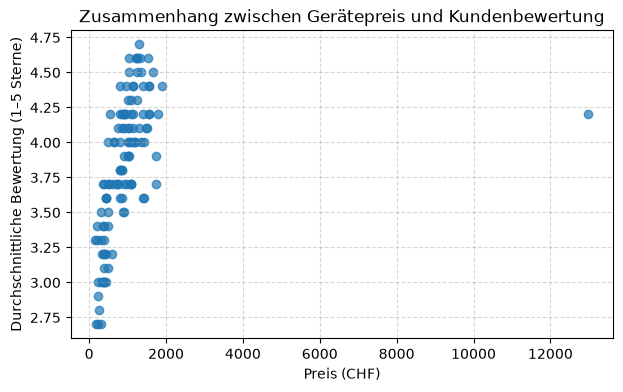

In [9]:
# Reviews einlesen und mit df_clean verbinden
df_reviews = pd.read_json('reviews.json')
df_C3 = pd.merge(df_clean, df_reviews, on='product_id', how='inner')

# Spearman-Rangkorrelation berechnen und auf 2 Dezimalstellen runden
corr_spearman = df_C3[['price_chf', 'avg_score']].corr(method='spearman').round(2)
print(corr_spearman)

# Streudiagramm erstellen
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(df_C3['price_chf'], df_C3['avg_score'], alpha=0.7)
ax.set_title('Zusammenhang zwischen Gerätepreis und Kundenbewertung')
ax.set_xlabel('Preis (CHF)')
ax.set_ylabel('Durchschnittliche Bewertung (1–5 Sterne)')
ax.grid(True, linestyle='--', alpha=0.5)
plt.show()


---
### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [ ]:
# Libraries
import os, platform, socket
from platform import python_version
from datetime import datetime

# Print system information
print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
print('Python Version:', python_version())
print('IP Address:', socket.gethostbyname(socket.gethostname()))
print('-----------------------------------')